# FreshRoute Canada Market Entry — Case Working Notes

**Client question:** Should FreshRoute — a mid-size U.S. online grocery delivery
company (~US$400M revenue, ~15 U.S. metro markets) — enter the Greater Toronto
Area (GTA) online grocery delivery market?

These are the case team's own working notes: how we framed the question, the
analysis we ran against each piece of the framing, and how it rolls up into a
recommendation. The final client-ready memo is generated at the end of this
notebook and also lives on its own at `outputs/recommendation_memo.md`.

> **Data disclaimer:** every figure used below is an illustrative, public-proxy
> estimate for the purposes of this case exercise. Competitor names are real;
> the market share, pricing, and unit-economics figures attached to them are
> not. See the repository README for the full disclaimer.

## Our approach

We don't start with a spreadsheet — we start with the question. The core
question ("should FreshRoute enter?") only becomes answerable once we break it
into an explicit, testable **hypothesis tree** (issue tree): mutually
exclusive, collectively exhaustive sub-hypotheses, each backed by a named
piece of analysis. Everything below exists to resolve one leaf of that tree.

In [1]:
import sys
from pathlib import Path

try:
    import market_entry_toolkit  # noqa: F401
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

OUTPUTS = Path.cwd().parent / "outputs"
EXHIBITS = OUTPUTS / "exhibits"
EXHIBITS.mkdir(parents=True, exist_ok=True)

## 1. Framing the question — the hypothesis tree

Before running a single number, we lay out what would have to be true for
"FreshRoute should enter the GTA" to hold. Four branches, each independently
testable: **market attractiveness**, **competitive intensity**, **capability
fit**, and **financial viability**. If any one of these fails outright, the
case for entry — at least in its current shape — fails with it.

In [2]:
from market_entry_toolkit.hypothesis_tree import build_case_tree, print_tree, Verdict

tree = build_case_tree()
print_tree(tree)  # every leaf starts PENDING — we resolve each one below

- **[0] FreshRoute should enter the Greater Toronto Area online grocery delivery market** ⏳
  *Analysis:* Synthesis of the four branches below (memo_synthesis.py)
  - **[1] The Canadian (GTA) online grocery market is large enough and growing fast enough to be worth entering** ⏳
    *Analysis:* Roll-up of market sizing and demand-trend sub-analyses
    - **[1.1] Top-down and bottom-up sizing agree the addressable market clears FreshRoute's minimum bar (~US$150M in year-5 category revenue)** ⏳
      *Analysis:* Top-down TAM from Canadian grocery e-commerce spend proxies, reconciled against a bottom-up build from GTA households x penetration x basket size x frequency (market_sizing.py)
    - **[1.2] Online grocery penetration in Canada is still rising, not saturating** ⏳
      *Analysis:* Trend read on online grocery penetration rate used in the bottom-up build (market_sizing.py)
  - **[2] Competitive intensity is manageable -- there is a defensible white-space position for a new entrant*

## 2. Market sizing

We size the market two independent ways and reconcile them rather than
averaging them together — the gap between a top-down and a bottom-up estimate
is itself informative, and a client will always ask about it.

Top-down: CA online grocery market ≈ $12.75B CAD → GTA online grocery ≈ $2.63B CAD → GTA online *delivery* ≈ $1183M CAD → realistic new-entrant SOM ≈ $201M CAD ($147M USD).
Bottom-up: 805,000 serviceable GTA households → 40,250 active customers at maturity (each ordering 52x/yr, $5,460 CAD/yr) → SOM ≈ $220M CAD ($160M USD).

The bottom-up estimate comes in 9% higher than top-down ($220M vs. $201M CAD). This is expected and explainable, not a red flag: top-down applies an average obtainable share across the *entire* GTA online-delivery market, including households FreshRoute would never target (outside delivery zones, price-insensitive club-store shoppers, etc.). Bottom-up instead targets FreshRoute's actual go-to-market segment -- digitally engaged, dual-income households inside serviceable postal codes -- which converts at a higher rate than the market-wide average baked into the top-down share assumption. In a client meeting we would present the bottom-up number as the operating plan

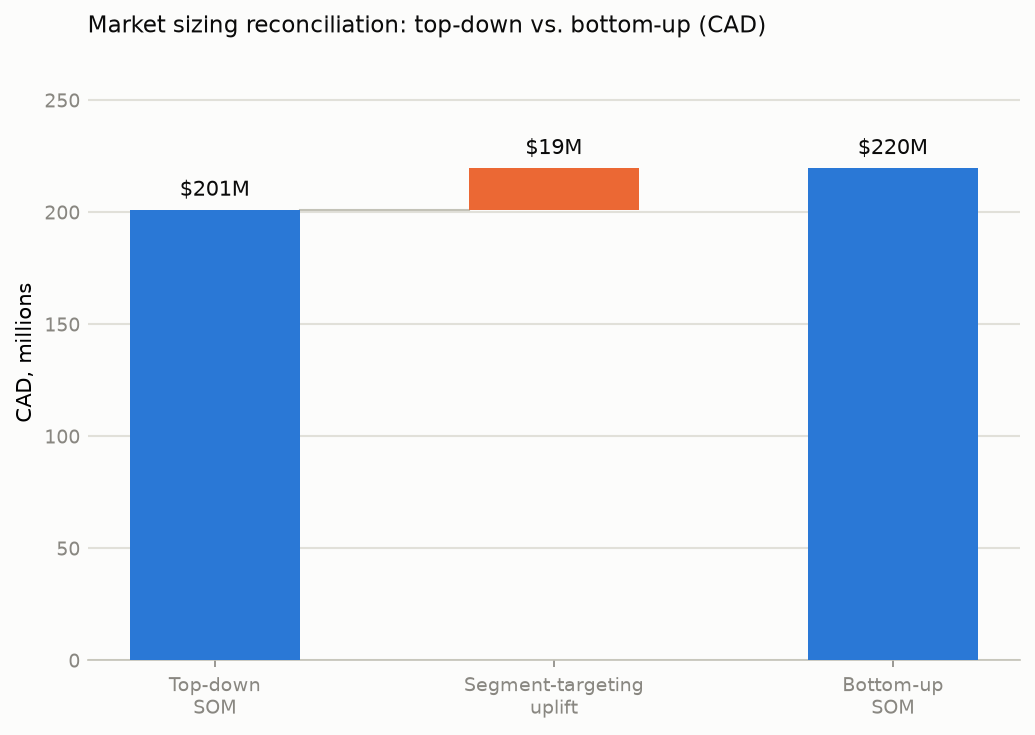

In [3]:
from market_entry_toolkit.market_sizing import reconcile, plot_reconciliation_waterfall

recon = reconcile()
print(recon.top_down.narrative())
print(recon.bottom_up.narrative())
print()
print(recon.explanation)

fig = plot_reconciliation_waterfall(recon, save_path=str(EXHIBITS / "market_sizing_waterfall.png"))
plt.show()

**Read:** both approaches land in the same ballpark (within ~9% of each
other) and both clear FreshRoute's ~US$150M minimum bar for a market worth
entering. The bottom-up number runs a bit higher because it targets
FreshRoute's actual go-to-market segment rather than the market-wide average
baked into the top-down share assumption — exactly the kind of gap we'd
expect, and exactly what we'd say in the room if a client asked "which number
is right?"

This resolves hypothesis **1.1**. We also need **1.2** — is this market still
growing, or about to saturate?

In [4]:
tree.find("1.1").resolve(
    finding=(
        f"Top-down SOM ≈ ${recon.top_down.som_cad/1e6:.0f}M CAD "
        f"(${recon.top_down.som_usd/1e6:.0f}M USD); bottom-up SOM ≈ "
        f"${recon.bottom_up.som_cad/1e6:.0f}M CAD (${recon.bottom_up.som_usd/1e6:.0f}M USD). "
        f"Both clear the ~US$150M minimum bar and sit within {recon.gap_pct_of_lower:.0%} of each other."
    ),
    verdict=Verdict.SUPPORTED,
)
tree.find("1.2").resolve(
    finding=(
        "Online grocery penetration assumed at 8.5% of total grocery spend nationally "
        "and still rising from a low-single-digit base several years ago; no signs of "
        "near-term saturation."
    ),
    verdict=Verdict.SUPPORTED,
)
print("[1] Market attractiveness rolls up to:", tree.find("1").rollup_verdict().value)

[1] Market attractiveness rolls up to: supported


## 3. Competitive benchmarking

Next: is this a market FreshRoute can actually win share in, or is it already
locked up by an incumbent? We structure the competitor set on share, pricing,
and positioning, then look for white space.

In [5]:
import pandas as pd
from market_entry_toolkit.competitive_benchmarking import (
    to_records, concentration_read, white_space_analysis, plot_positioning_map,
)

df = pd.DataFrame(to_records())
df

,name,business_model,est_market_share_pct,price_index,curation_index,avg_order_value_cad,est_gross_margin_pct,differentiation
0,Instacart Canada,Marketplace (picks/delivers from partner retai...,30.0,3,2,95.0,0.22,"Breadth -- widest retailer selection, weakest ..."
1,PC Express (Loblaws),"Retailer-owned, mostly click-and-collect + own...",25.0,2,2,110.0,0.24,"Private label + loyalty (PC Optimum) lock-in, ..."
2,Voila by Sobeys,"Delivery-only, automated dark-store fulfillment",15.0,4,4,130.0,0.27,"Premium/curated assortment and reliability, li..."
3,Walmart Canada Grocery,"Retailer-owned delivery + pickup, value positi...",20.0,1,1,85.0,0.18,"Lowest price, broad but low-curation assortment"
4,Amazon Fresh Canada,Prime-linked marketplace delivery,10.0,3,3,90.0,0.20,"Prime bundling and convenience, inconsistent f..."
5,FreshRoute (proposed),Partner-store picking + owned last-mile courie...,0.0,3,4,105.0,0.23,Mid-price reliability + fresh/local curation -...


HHI = 2,250 (moderately concentrated); largest incumbent holds 30% share. No competitor exceeds ~30% -- the market is fragmented enough that a well-differentiated new entrant can realistically take share without displacing a single dominant player.

On a price (1=value, 5=premium) x curation (1=broad/mass, 5=curated/specialty) grid, the proposed FreshRoute position (price=3, curation=4) sits in open space between the two nearest incumbents, Voila by Sobeys and Amazon Fresh Canada. Walmart Canada wins on price but offers minimal curation; Voila by Sobeys offers strong curation but at a premium price and with limited coverage. FreshRoute's mid-price, high-curation position -- reliability plus fresh/local sourcing without Voila's premium markup -- is not directly contested by any incumbent at scale, and matches FreshRoute's existing brand positioning in its US markets.


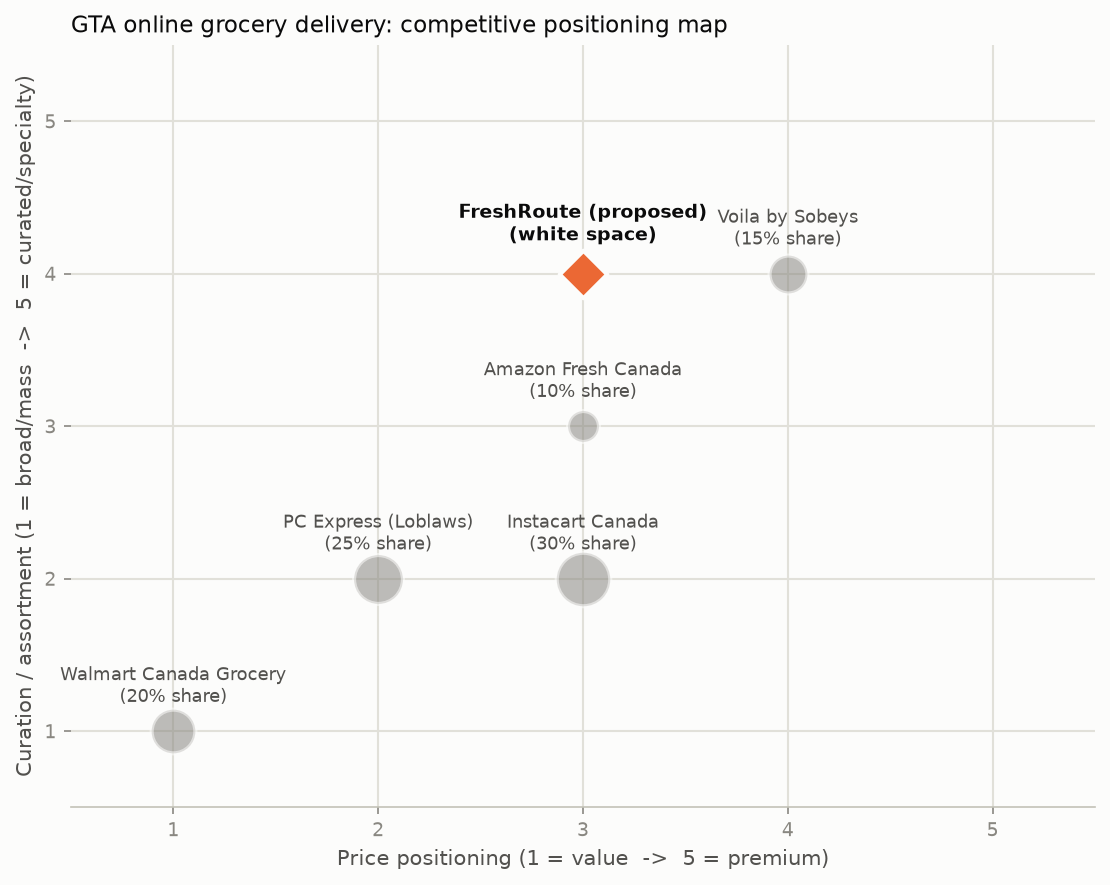

In [6]:
print(concentration_read())
print()
print(white_space_analysis())

fig = plot_positioning_map(save_path=str(EXHIBITS / "competitive_positioning_map.png"))
plt.show()

**Read:** the market is fragmented (HHI ≈ 2,250, no player above ~30%
share) — this is a market a well-differentiated entrant can realistically take
share in, not one where a single incumbent forecloses entry. And there's real
white space: nobody currently combines FreshRoute's mid-price, high-curation
positioning at scale. That resolves **2.1** and **2.2**.

In [7]:
tree.find("2.1").resolve(finding=concentration_read(), verdict=Verdict.SUPPORTED)
tree.find("2.2").resolve(finding=white_space_analysis(), verdict=Verdict.SUPPORTED)
print("[2] Competitive intensity rolls up to:", tree.find("2").rollup_verdict().value)

[2] Competitive intensity rolls up to: supported


## 4. Capability fit

This branch is a qualitative review rather than a separately-quantified
module (per the case scope) — does FreshRoute's existing operating model
actually transfer to Canada, or does entry require capabilities it doesn't
have?

In [8]:
tree.find("3.1").resolve(
    finding=(
        "FreshRoute's partner-store picking + owned courier model mirrors Instacart's "
        "proven operating model in Canada; no new warehouse buildout required to launch."
    ),
    verdict=Verdict.SUPPORTED,
)
tree.find("3.2").resolve(
    finding=(
        "GST/HST registration, cross-border payment processing, and Ontario employment "
        "law for courier classification are all navigable but require dedicated "
        "legal/compliance setup work not needed in FreshRoute's US markets — a real "
        "but non-blocking cost and timeline item."
    ),
    verdict=Verdict.PARTIALLY_SUPPORTED,
)
print("[3] Capability fit rolls up to:", tree.find("3").rollup_verdict().value)

[3] Capability fit rolls up to: partially supported


## 5. Financial feasibility

Market attractiveness, competitive white space, and capability fit all look
supportive. The last — and often decisive — branch: does the entry actually
pay for itself? We build a 5-year P&L off the bottom-up SOM as the year-5
revenue anchor, under base/upside/downside scenarios, and compute payback and
NPV/IRR.

Base: Y5 revenue $220M, Y5 EBITDA $-1.6M, payback no payback within 5yr, NPV $-44.6M, IRR n/m
Upside: Y5 revenue $275M, Y5 EBITDA $10.5M, payback no payback within 5yr, NPV $-21.3M, IRR -18.2%
Downside: Y5 revenue $154M, Y5 EBITDA $-16.8M, payback no payback within 5yr, NPV $-64.9M, IRR n/m


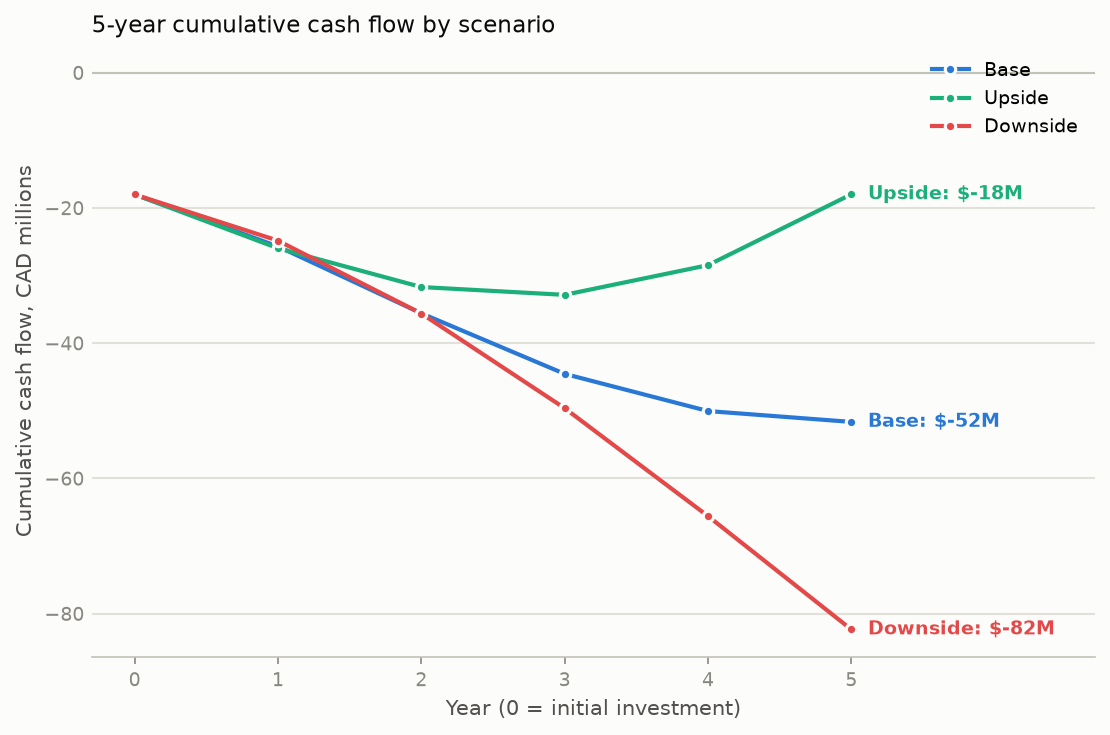

In [9]:
from market_entry_toolkit.financial_feasibility import run_all_scenarios, plot_scenario_cashflows

scenarios = run_all_scenarios(recon.bottom_up.som_cad)
base, upside, downside = scenarios["base"], scenarios["upside"], scenarios["downside"]

for s in scenarios.values():
    print(s.summary_line())

fig = plot_scenario_cashflows(scenarios, save_path=str(EXHIBITS / "financial_scenarios.png"))
plt.show()

**Read:** this is the uncomfortable finding. At the full ~$18M CAD
upfront launch investment modeled, **none of the three scenarios pay back
within the 5-year horizon**, and NPV is negative even in the upside case.
That's not a red flag on the model — it's consistent with how capital-
intensive and slow-to-profit on-demand grocery delivery has proven to be
industry-wide. It does mean hypothesis **4.1 fails outright** as stated, and
**4.2 is only partially supported**: NPV is negative within our 5-year
window (a modeling limitation, since we exclude terminal value beyond year 5
when base/upside cash flow is solidly positive and growing), but the
downside's max loss is a bounded, survivable risk relative to FreshRoute's
existing ~US$400M revenue base — not a bet-the-company scenario.

In [10]:
def _fmt_payback(years):
    return f"{years:.1f}yr" if years is not None else "no payback within 5yr"

tree.find("4.1").resolve(
    finding=(
        f"At the full-scale ${base.assumptions.initial_investment_cad/1e6:.0f}M CAD launch "
        f"investment modeled, none of the three scenarios pay back within 5 years "
        f"(base: {_fmt_payback(base.payback_period_years)}, "
        f"upside: {_fmt_payback(upside.payback_period_years)}, "
        f"downside: {_fmt_payback(downside.payback_period_years)}) — online grocery "
        "delivery is a capital-intensive, slow-to-profit category, consistent with the "
        "real-world path of comparable delivery businesses."
    ),
    verdict=Verdict.NOT_SUPPORTED,
)
tree.find("4.2").resolve(
    finding=(
        f"NPV is negative in all three scenarios within the modeled 5-year horizon "
        f"(base ${base.npv_cad/1e6:.0f}M, upside ${upside.npv_cad/1e6:.0f}M, "
        f"downside ${downside.npv_cad/1e6:.0f}M CAD) — a modeling limitation as much as "
        "a business one, since the model excludes terminal value beyond year 5, when "
        "base/upside EBITDA is solidly positive and growing. The downside's "
        f"${downside.npv_cad/1e6:.0f}M CAD max loss is a bounded, survivable risk against "
        "FreshRoute's ~US$400M existing revenue base."
    ),
    verdict=Verdict.PARTIALLY_SUPPORTED,
)
print("[4] Financial viability rolls up to:", tree.find("4").rollup_verdict().value)

[4] Financial viability rolls up to: not supported


## 6. Rolling it up

With all eight leaves resolved, here's the full tree and its overall
rollup verdict.

In [11]:
print(tree.to_markdown())
print()
print("ROOT ROLLUP:", tree.rollup_verdict().value)

- **[0] FreshRoute should enter the Greater Toronto Area online grocery delivery market** ❌
  *Analysis:* Synthesis of the four branches below (memo_synthesis.py)
  - **[1] The Canadian (GTA) online grocery market is large enough and growing fast enough to be worth entering** ✅
    *Analysis:* Roll-up of market sizing and demand-trend sub-analyses
    - **[1.1] Top-down and bottom-up sizing agree the addressable market clears FreshRoute's minimum bar (~US$150M in year-5 category revenue)** ✅
      *Analysis:* Top-down TAM from Canadian grocery e-commerce spend proxies, reconciled against a bottom-up build from GTA households x penetration x basket size x frequency (market_sizing.py)
      *Finding:* Top-down SOM ≈ $201M CAD ($147M USD); bottom-up SOM ≈ $220M CAD ($160M USD). Both clear the ~US$150M minimum bar and sit within 9% of each other.
    - **[1.2] Online grocery penetration in Canada is still rising, not saturating** ✅
      *Analysis:* Trend read on online grocery penetration

A strict roll-up says **not supported** — and that's the correct,
honest answer to the question *as originally framed* ("enter via a full-scale
$18M CAD build now"). But a case team's job isn't to stop at "no." Three of
four branches are strongly supportive, and the fourth fails specifically
because of the capital intensity of a full-scale launch — not because the
opportunity itself is bad. The right move is to change the shape of the ask:
**recommend entry, restructured as a milestone-gated phased investment**
(a smaller, partnership-based pilot in a subset of the GTA to prove out
retention and delivery-cost assumptions before committing the full build-out),
with a formal reassessment of the payback economics at the 18–24 month mark.
That's the stance we hand to the synthesis step below.

## 7. Synthesis — drafting the recommendation memo

This is the AI-assisted step. We hand the LLM the case team's own findings —
not raw data, and not the decision itself — and ask it to *write up* the
recommendation we've already reached, in Situation/Complication/Resolution
form. The full system + user prompt are in `memo_synthesis.py`, fully
inspectable and printed below before we call it.

If `ANTHROPIC_API_KEY` isn't set (as in the environment this notebook was
authored in), `synthesize_memo()` automatically falls back to a deterministic,
offline template — no black box either way.

In [12]:
from market_entry_toolkit.memo_synthesis import (
    CaseInputs, SYSTEM_PROMPT, build_user_prompt, synthesize_memo,
    verify_traceability, print_review_checklist,
)

market_sizing_summary = (
    f"**Market sizing.** {recon.top_down.narrative()} {recon.bottom_up.narrative()} "
    f"{recon.explanation}"
)
competitive_summary = (
    f"**Competitive benchmarking.** {concentration_read()} {white_space_analysis()}"
)
financial_summary = (
    f"**Financial feasibility.** {base.summary_line()}. {upside.summary_line()}. "
    f"{downside.summary_line()}. None of the three scenarios achieve payback within "
    f"the modeled 5-year horizon under the full ${base.assumptions.initial_investment_cad/1e6:.0f}M "
    "CAD launch investment; NPV is negative in all three at a 10% discount rate over "
    "this horizon, though the model excludes terminal value beyond year 5, when "
    "base/upside cash flow is solidly positive."
)
recommendation_hint = (
    "Conditional go: the market opportunity, competitive white space, and operating-"
    "model fit all clear the bar. The standalone financial case for a full ~$18M CAD "
    "upfront launch does not clear payback within a 5-year horizon under any modeled "
    "scenario. Recommend proceeding, but restructured as a milestone-gated phased "
    "investment — a smaller, partnership-based pilot in a subset of the GTA to "
    "prove out retention, delivery cost, and CAC assumptions — with a formal "
    "reassessment of full-scale build-out economics at the 18–24 month mark."
)

case_inputs = CaseInputs(
    client_name="FreshRoute",
    core_question="Should FreshRoute enter the Greater Toronto Area (GTA) online grocery delivery market?",
    hypothesis_tree_markdown=tree.to_markdown(),
    supporting_evidence_bullets="\n".join(f"- {b}" for b in tree.branch_summary_bullets()),
    overall_verdict=(
        f"{tree.rollup_verdict().value} for a full-scale launch as originally framed "
        "-- three of four branches are strongly supportive, and the fourth (financial "
        "viability) fails specifically because of the capital intensity of a full-scale "
        "build, not because the underlying opportunity is bad. That reframes the ask "
        "rather than closing it -- see the recommendation below."
    ),
    market_sizing_summary=market_sizing_summary,
    competitive_summary=competitive_summary,
    financial_summary=financial_summary,
    recommendation_hint=recommendation_hint,
)

print("=== SYSTEM PROMPT ===")
print(SYSTEM_PROMPT)
print("=== USER PROMPT (first 600 chars) ===")
print(build_user_prompt(case_inputs)[:600], "...")

=== SYSTEM PROMPT ===
You are a senior case-team member at a top-tier management consultancy, writing the executive recommendation memo at the end of a market-entry strategy engagement. You write in the Situation-Complication-Resolution structure: crisp, declarative, numbers-forward, no hedging, no filler, no restating the obvious. One to two pages maximum.

Hard rules:
1. Use ONLY the facts, figures, and conclusions given to you in the case findings below. Do not introduce any statistic, competitor fact, or financial figure that is not present in the input. If you need a transition or framing sentence, keep it qualitative -- never invent a number to make a sentence flow better.
2. The bottom-line recommendation is given to you (see "Required recommendation stance" in the user message). Your job is to write it up persuasively and precisely from the evidence provided, not to reach your own independent recommendation or to soften/contradict the given stance.
3. Structure: a short **Situa

In [13]:
memo_text, mode = synthesize_memo(case_inputs)
print(f"Synthesis mode used: {mode}")
print()
print(memo_text)

Synthesis mode used: template

# Recommendation Memo: FreshRoute

**Question:** Should FreshRoute enter the Greater Toronto Area (GTA) online grocery delivery market?

## Situation

FreshRoute asked us to determine whether entering the Greater Toronto Area online grocery delivery market is a good use of capital, and if so, how. We structured the question into four testable hypotheses -- market attractiveness, competitive intensity, capability fit, and financial viability -- and ran a dedicated analysis against each.

## Complication

**Market sizing.** Top-down: CA online grocery market ≈ $12.75B CAD → GTA online grocery ≈ $2.63B CAD → GTA online *delivery* ≈ $1183M CAD → realistic new-entrant SOM ≈ $201M CAD ($147M USD). Bottom-up: 805,000 serviceable GTA households → 40,250 active customers at maturity (each ordering 52x/yr, $5,460 CAD/yr) → SOM ≈ $220M CAD ($160M USD). The bottom-up estimate comes in 9% higher than top-down ($220M vs. $201M CAD). This is expected and explainable, no

### Human-in-the-loop review

An LLM-drafted client memo never ships un-reviewed. Before this draft goes
anywhere near a client, a case-team member works through this checklist —
plus the automated traceability check below, which flags any source figure
that silently dropped out of the draft (it can't catch fabrication, which is
exactly why the human checklist item 1 exists).

In [14]:
print_review_checklist()
print()
warnings = verify_traceability(case_inputs, memo_text)
print("Traceability warnings:", warnings if warnings else "none — all source figures present in the draft")

Human-in-the-loop review checklist (complete before sharing):
  [ ] 1. Every number in the draft traces back to market_sizing.py, competitive_benchmarking.py, or financial_feasibility.py output -- none were introduced by the LLM.
  [ ] 2. The recommendation stated in the memo matches `recommendation_hint` and the hypothesis-tree rollup verdict; the LLM did not soften, hedge, or override the given stance.
  [ ] 3. No competitor claim in the memo goes beyond what's in competitive_benchmarking.py (no invented market share, pricing, or positioning detail).
  [ ] 4. Tone and length are appropriate for a client CEO audience (one to two pages, no jargon, no padding).
  [ ] 5. The 'Supporting evidence' section correctly reflects the hypothesis tree's per-branch verdicts.
  [ ] 6. A named case-team reviewer has read the full draft end-to-end and signed off before it is shared outside the team.

Traceability warnings: none — all source figures present in the draft


## 8. Finalize the client-ready memo

We assemble the reviewed memo with its three supporting exhibits into the
final deliverable, saved to `outputs/recommendation_memo.md`.

In [15]:
exhibits_section = '''
## Exhibits

### Exhibit 1 — Market sizing reconciliation
![Market sizing waterfall](exhibits/market_sizing_waterfall.png)

### Exhibit 2 — Competitive positioning map
![Competitive positioning map](exhibits/competitive_positioning_map.png)

### Exhibit 3 — 5-year cumulative cash flow by scenario
![Financial scenarios](exhibits/financial_scenarios.png)
'''

footer = (
    f"\n---\n*This memo was AI-drafted ({mode} mode — see `memo_synthesis.py`) from the "
    "quantitative outputs of `market_sizing.py`, `competitive_benchmarking.py`, and "
    "`financial_feasibility.py`, and reviewed against the human-in-the-loop checklist "
    "above before being finalized. All data is illustrative/public-proxy data — see "
    "the README for the full disclaimer. This is a case-study exercise, not investment "
    "advice.*\n"
)

final_memo = memo_text + exhibits_section + footer

memo_path = OUTPUTS / "recommendation_memo.md"
memo_path.write_text(final_memo, encoding="utf-8")
print(f"Wrote {memo_path} ({len(final_memo)} chars)")

Wrote /home/user/market-entry-case-toolkit/outputs/recommendation_memo.md (5460 chars)


## Case team wrap-up

Where a real engagement would go from here: size the phased-pilot investment
precisely (this notebook deliberately doesn't — see `financial_feasibility.py`
docstring on scope), pressure-test the GST/HST and courier-classification
compliance timeline with local counsel, and design the specific retention/CAC
milestones that would trigger the full-scale build-out decision at the
18–24 month mark.